# BrainScan — dataset exploration and image validation

Run the blocks in order with the project's `.venv` Python kernel.
This notebook inspects the original dataset without moving, deleting, resizing,
or splitting files. We will add later stages as we work through them.

**Pillow checks the image contents. Pandas organizes the findings.**
A valid filename or `.jpg` extension does not guarantee a readable image.
Conversely, a readable image is not necessarily correctly labeled or medically suitable.

## Block 0 — Imports and dataset path

Locate the project whether the notebook starts in the project root or in `notebooks/`.
These imports do not load TensorFlow or start training.

In [3]:
from pathlib import Path
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, ImageOps
from IPython.display import display

PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "pyproject.toml").is_file() and (folder / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the Brain Scan 2 project.")

DATA_DIR = PROJECT_ROOT / "data"
REPORT_DIR = PROJECT_ROOT / "reports" / "data_quality"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
ImageFile.LOAD_TRUNCATED_IMAGES = False  # Do not silently accept truncated images.
SEED = 42
print("Dataset:", DATA_DIR)

Dataset: c:\Users\ycode\Desktop\projects\sprint 1\Brain Scan 2\data


## Block 1 — Build an inventory DataFrame

One row represents one file under an `images/` folder. `split` and `category`
come from its parent folders; these are dataset labels, not verified diagnoses.
The corresponding annotation must have the same filename stem under `labels/`.
We keep every file in the inventory so unexpected extensions remain visible.

In [5]:
rows = []
for split_dir in sorted(DATA_DIR.iterdir()):
    if not split_dir.is_dir():
        continue
    for category_dir in sorted(split_dir.iterdir()):
        image_dir = category_dir / "images"
        if not image_dir.is_dir():
            continue
        for image_path in sorted(image_dir.iterdir()):
            if not image_path.is_file():
                continue
            label_path = category_dir / "labels" / (image_path.stem + ".txt")
            rows.append({
                "split": split_dir.name,
                "category": category_dir.name,
                "relative_path": image_path.relative_to(PROJECT_ROOT).as_posix(),
                "extension": image_path.suffix.lower(),
                "size_bytes": image_path.stat().st_size,
                "annotation_exists": label_path.is_file(),
            })

inventory = pd.DataFrame(rows)
if inventory.empty:
    raise ValueError(f"No files found under {DATA_DIR}/<split>/<category>/images/.")

print(f"Files inventoried: {len(inventory):,}")
display(inventory.head())
display(pd.crosstab(inventory["category"], inventory["split"], margins=True))
display(inventory["extension"].value_counts().rename("files").to_frame())

Files inventoried: 5,249


,split,category,relative_path,extension,size_bytes,annotation_exists
0,Train,Glioma,data/Train/Glioma/images/gg (1).jpg,.jpg,21150,True
1,Train,Glioma,data/Train/Glioma/images/gg (103).jpg,.jpg,23759,True
2,Train,Glioma,data/Train/Glioma/images/gg (104).jpg,.jpg,26727,True
3,Train,Glioma,data/Train/Glioma/images/gg (105).jpg,.jpg,28618,True
4,Train,Glioma,data/Train/Glioma/images/gg (106).jpg,.jpg,28825,True


split,Train,Val,All
category,,,
Glioma,1153,136,1289
Meningioma,1449,140,1589
No Tumor,711,100,811
Pituitary,1424,136,1560
All,4737,512,5249


,files
extension,
.jpg,5249


## Block 2 — Verify and fully decode each image with Pillow

`verify()` checks file structure. We reopen the file and call `load()` to force
pixel decoding, which can expose truncation that a header check misses.
`try/except` records failures and lets the scan continue.
Warnings are recorded for review; they are not automatically treated as corruption.
This block may take a few minutes. Progress is printed every 500 files.

In [9]:
invalid_images = []

for relative_path in inventory["relative_path"]:
    try:
        with Image.open(PROJECT_ROOT / relative_path) as image:
            image.load()

    except Exception as error:
        invalid_images.append(relative_path)
        print(f"Cannot read {relative_path}: {error}")

print("Images checked:", len(inventory))
print("Unreadable images:", len(invalid_images))

Images checked: 5249
Unreadable images: 0


category
Meningioma    1589
Pituitary     1560
Glioma        1289
No Tumor       811
Name: count, dtype: int64

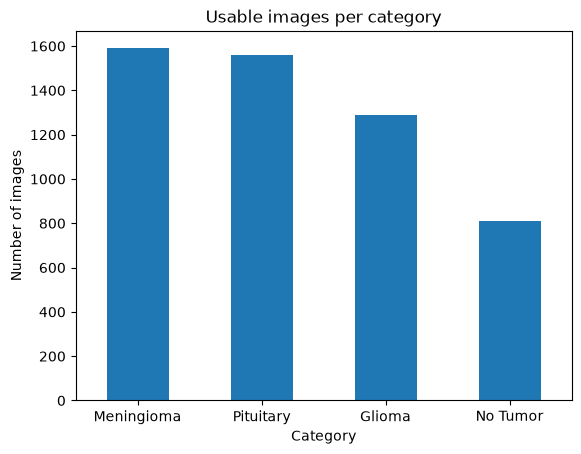

In [ ]:
usable_images = inventory.loc[
    ~inventory["relative_path"].isin(invalid_images)
].copy()

class_counts = usable_images["category"].value_counts()
display(class_counts)

# Plot the counts.
class_counts.plot.bar(
    title="number of usable images per category",
    xlabel="category",
    ylabel="number of usable images"
    rot=0
)
plt.show()

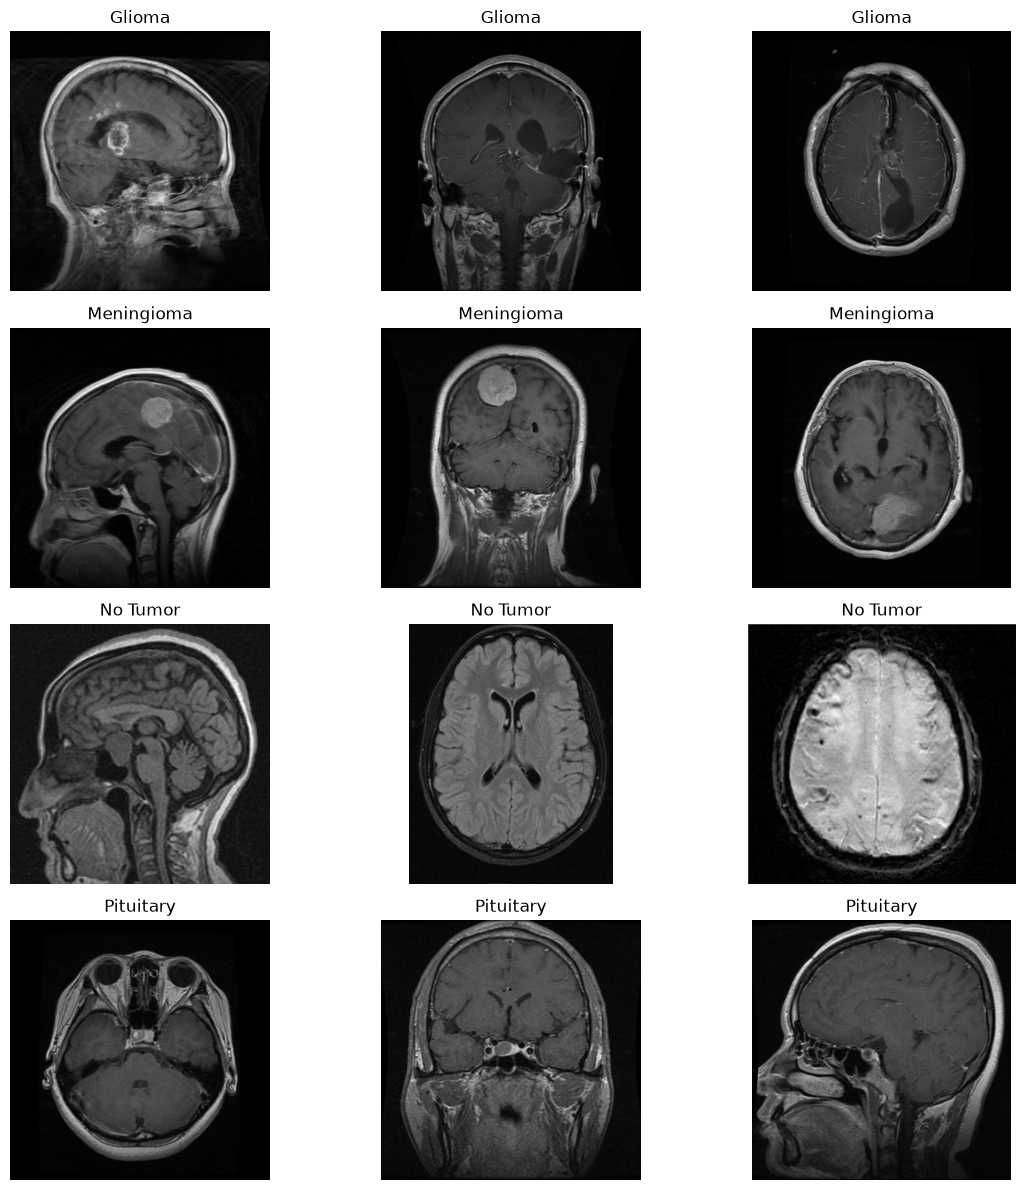

In [ ]:
# Create one row of plots per category, with three images per row.
categories = sorted(usable_images["category"].unique())
fig, axes = plt.subplots(len(categories), 3, figsize=(12, 12))

for row, category in enumerate(categories):
    category_images = usable_images.loc[
        usable_images["category"] == category
    ]

    samples = category_images.sample(n=3, random_state=42)

    for column, relative_path in enumerate(samples["relative_path"]):
        with Image.open(PROJECT_ROOT / relative_path) as image:
            axes[row, column].imshow(image.convert("RGB"))

        axes[row, column].set_title(category)
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

In [12]:
import hashlib

fingerprints = []

for relative_path in usable_images["relative_path"]:
    with open(PROJECT_ROOT / relative_path, "rb") as file:
        fingerprint = hashlib.file_digest(file, "sha256").hexdigest()

    fingerprints.append(fingerprint)

usable_images["sha256"] = fingerprints

duplicates = usable_images.loc[
    usable_images.duplicated(subset="sha256", keep=False)
]

print("Images belonging to duplicate groups:", len(duplicates))

display(
    duplicates[["relative_path", "category", "split", "sha256"]]
    .sort_values("sha256")
)

Images belonging to duplicate groups: 2564


,relative_path,category,split,sha256
4148,data/Train/Pituitary/images/Te-pi_0049.jpg,Pituitary,Train,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...
4038,data/Train/Pituitary/images/p (757).jpg,Pituitary,Train,004f9655d6baf78b265cc9ae3766e250550d13a82e0405...
2031,data/Train/Meningioma/images/Tr-me_0383.jpg,Meningioma,Train,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...
1494,data/Train/Meningioma/images/m2 (112).jpg,Meningioma,Train,008d21cf043b4a4ae6c9e28459818fe93c07df9ff9d521...
3510,data/Train/Pituitary/images/p (278).jpg,Pituitary,Train,009bb0f6f6174828718de2b4566718aabaf61e819e5676...
...,...,...,...,...
1299,data/Train/Meningioma/images/m (9).jpg,Meningioma,Train,ff3f14bb91784fd7068c728cd8eb6debd8ecb891fd4392...
1286,data/Train/Meningioma/images/m (72).jpg,Meningioma,Train,ff7dfd036e3e8661030f4d65736a070f79054404c07b0a...
1935,data/Train/Meningioma/images/Tr-me_0145.jpg,Meningioma,Train,ff7dfd036e3e8661030f4d65736a070f79054404c07b0a...
1465,data/Train/Meningioma/images/m1(80).jpg,Meningioma,Train,ffde8c9d95515daa525cce3d7076fb9394b986feaeebe1...


In [13]:
import hashlib

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "classification"

rows = []

for split in ["train", "validation", "test"]:
    for image_path in sorted((SPLIT_DIR / split).glob("*/*")):
        if not image_path.is_file():
            continue

        with image_path.open("rb") as file:
            fingerprint = hashlib.file_digest(file, "sha256").hexdigest()

        rows.append({
            "split": split,
            "relative_path": image_path.relative_to(PROJECT_ROOT).as_posix(),
            "sha256": fingerprint,
        })

split_check = pd.DataFrame(rows)

duplicates_after_split = split_check.loc[
    split_check.duplicated(subset="sha256", keep=False)
]

print("Images checked:", len(split_check))
print("Images in duplicate groups:", len(duplicates_after_split))
display(duplicates_after_split)

Images checked: 3913
Images in duplicate groups: 0


,split,relative_path,sha256


In [15]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train",
    image_size=(256, 256),
    batch_size=16,
    color_mode="rgb",
    label_mode="int",
    shuffle=True,
    seed=42
)

class_names = train_ds.class_names
print("Class order:", class_names)

Found 2739 files belonging to 4 classes.
Class order: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
